# BRIDGE — Inteligência Artificial & Machine Learning

**FIAP Global Solution 2026.2 · CitizenTech · Engenharia de Software**

## Objetivo

Construir e avaliar um componente de Machine Learning para apoiar a triagem de ocorrências de infraestrutura urbana registradas no BRIDGE. O modelo recebe os campos textuais `titulo` e `descricao` e sugere uma categoria compatível com o domínio real do aplicativo.

A tarefa é uma **classificação multiclasse de texto**. O modelo não calcula prioridade, não substitui a categoria escolhida pelo cidadão e não analisa fotografias. A prioridade continua sendo calculada pelas regras determinísticas já implementadas em `backend/app/services/prioridade.py`.

## Escopo e decisões

- **Entradas disponíveis e utilizadas:** `titulo` e `descricao`.
- **Saída:** `categoria_sugerida`, uma das cinco categorias oficiais do backend.
- **Algoritmo:** TF-IDF para representação do texto + Regressão Logística multiclasse.
- **Métrica principal:** F1-score macro, para dar o mesmo peso às cinco categorias.
- **Validação:** conjunto de teste estratificado separado antes da busca de hiperparâmetros; validação cruzada estratificada apenas no conjunto de treino.
- **Reprodutibilidade:** sementes aleatórias fixas e geração automática da base sintética. Não é necessário fazer upload manual de CSV.

> **Transparência dos dados:** o repositório fornecido não contém uma base real rotulada de relatos textuais. Por isso, este notebook gera uma base **sintética e simulada**, documentada abaixo. As métricas demonstram o funcionamento técnico em padrões simulados; não comprovam desempenho em ocorrências reais.

## 1. Problema e dados

O BRIDGE precisa ajudar a organizar relatos em categorias padronizadas. O modelo aprende associações entre expressões do título/descrição e as classes do domínio. A categoria que o cidadão selecionou não é usada como entrada: ela seria uma informação diretamente ligada ao rótulo e causaria vazamento de dados.

### Classes oficiais

1. `CALCADA_DANIFICADA`
2. `BURACO`
3. `ILUMINACAO_DEFEITUOSA`
4. `OBSTACULO_CIRCULACAO`
5. `OUTRO`

Cada registro sintético tem `titulo`, `descricao` e `categoria`. Não são usados dados pessoais, coordenadas, imagens ou atributos inventados que não sejam necessários para esta tarefa.

In [1]:
# 2. Bibliotecas e reprodutibilidade
from pathlib import Path
import json
import platform
import random
import re
import sys
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

CATEGORIAS = [
    "CALCADA_DANIFICADA",
    "BURACO",
    "ILUMINACAO_DEFEITUOSA",
    "OBSTACULO_CIRCULACAO",
    "OUTRO",
]
VERSAO_MODELO = "bridge-text-classifier-1.0.0"

# No repositório: grava dentro de ia_ml/. No Colab/Jupyter isolado: cria uma pasta local.
candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
raiz_projeto = next((p.resolve() for p in candidatos if (p / "backend" / "app" / "enums.py").exists()), None)
if raiz_projeto:
    PASTA_IA = raiz_projeto / "ia_ml"
else:
    PASTA_IA = Path.cwd() / "bridge_ia_ml_output"

PASTA_DATASET = PASTA_IA / "dataset"
PASTA_ARTIFATOS = PASTA_IA / "artifacts"
PASTA_DATASET.mkdir(parents=True, exist_ok=True)
PASTA_ARTIFATOS.mkdir(parents=True, exist_ok=True)

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__} | scikit-learn: {sklearn.__version__} | joblib: {joblib.__version__}")
print(f"Pasta de saída: {PASTA_IA.resolve()}")

Python: 3.13.5
pandas: 2.2.3 | scikit-learn: 1.8.0 | joblib: 1.5.3
Pasta de saída: C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml


## 3. Geração da base sintética

A base é simulada a partir de modelos de títulos e descrições escritos para representar relatos urbanos plausíveis. Variações de localização, contexto e linguagem são combinadas aleatoriamente. A distribuição é balanceada para permitir a comparação entre classes. O gerador usa semente fixa (`42`) para reproduzir os mesmos registros.

A simulação não substitui coleta de relatos reais nem revisão de especialistas. O arquivo CSV é salvo pelo próprio notebook para que a origem e a base utilizada fiquem junto da entrega.

In [2]:
# 4. Gerador de dados sintéticos — sem upload externo
GERADOR = {
    "CALCADA_DANIFICADA": {
        "titulos": [
            "Calçada com piso quebrado", "Desnível no passeio público", "Piso tátil danificado",
            "Lajotas soltas na calçada", "Calçada afundada", "Rampa de acessibilidade irregular",
            "Buracos pequenos no passeio", "Concreto rachado na calçada", "Meio-fio danificado",
            "Piso da passagem está desnivelado", "Calçada com placas levantadas", "Trecho de passeio deteriorado",
        ],
        "descricoes": [
            "O piso apresenta rachaduras e partes soltas, causando risco de tropeço para pedestres.",
            "Há um desnível no caminho de pedestres e a superfície está quebrada em vários pontos.",
            "As placas do piso tátil estão soltas ou faltando, dificultando a orientação de pessoas com deficiência visual.",
            "A calçada afundou perto da guia e precisa de reparo no revestimento.",
            "O concreto está trincado e algumas lajotas se movimentam quando alguém passa.",
            "A rampa de acesso está danificada e não permite uma circulação confortável.",
            "O passeio tem partes elevadas e outras rebaixadas, prejudicando a caminhada.",
            "O revestimento se soltou e deixou uma parte irregular no trajeto de pedestres.",
            "O piso está deteriorado junto ao meio-fio e pode provocar quedas.",
            "A passagem de pedestres apresenta rachaduras, placas quebradas e falta de nivelamento.",
        ],
    },
    "BURACO": {
        "titulos": [
            "Buraco aberto na rua", "Cratera no asfalto", "Pavimento com buraco profundo",
            "Buraco próximo ao cruzamento", "Asfalto cedendo na via", "Grande buraco na pista",
            "Buraco surgiu após a chuva", "Pavimentação danificada", "Trecho da rua com crateras",
            "Buraco perto da faixa de pedestres", "Via com pavimento afundado", "Reparo de asfalto necessário",
        ],
        "descricoes": [
            "Existe um buraco profundo no asfalto que pode danificar pneus e causar acidentes.",
            "A pavimentação cedeu e formou uma cratera na pista de circulação de veículos.",
            "O buraco acumula água quando chove e fica difícil perceber sua profundidade.",
            "Há uma abertura no asfalto perto do cruzamento e os motoristas precisam desviar.",
            "O pavimento está rompido e apresenta um buraco no meio da faixa de rolamento.",
            "A superfície da rua afundou, deixando uma cavidade que oferece risco ao trânsito.",
            "O asfalto se desfez neste trecho e há pedras soltas ao redor do buraco.",
            "A pista apresenta uma cratera que exige manutenção do pavimento.",
            "O buraco aumentou depois das chuvas e ocupa parte da faixa de veículos.",
            "Há um defeito no asfalto com profundidade suficiente para causar danos aos veículos.",
        ],
    },
    "ILUMINACAO_DEFEITUOSA": {
        "titulos": [
            "Poste com lâmpada apagada", "Luminária pública não funciona", "Rua sem iluminação",
            "Luz do poste piscando", "Ponto escuro na via", "Lâmpada queimada na praça",
            "Iluminação pública defeituosa", "Poste permanece apagado à noite", "Luminária com falha",
            "Trecho sem luz noturna", "Braço de iluminação apagado", "Iluminação oscilando na rua",
        ],
        "descricoes": [
            "A lâmpada do poste não acende durante a noite e o trecho fica escuro.",
            "A luminária pública está apagada há alguns dias, reduzindo a visibilidade de pedestres.",
            "A luz do poste pisca continuamente e depois fica apagada.",
            "Há um ponto sem iluminação na rua, dificultando enxergar a calçada à noite.",
            "O equipamento de iluminação não está funcionando mesmo quando escurece.",
            "A lâmpada da praça queimou e uma parte do espaço público ficou sem luz.",
            "O poste apresenta falha elétrica aparente e a luminária não ilumina a passagem.",
            "A iluminação está intermitente e deixa o local escuro em alguns momentos.",
            "A via ficou sem luz depois que a luminária parou de funcionar.",
            "O braço de iluminação está instalado, mas a lâmpada permanece apagada.",
        ],
    },
    "OBSTACULO_CIRCULACAO": {
        "titulos": [
            "Entulho bloqueia a calçada", "Obstáculo na passagem de pedestres", "Galhos caídos na calçada",
            "Material de obra ocupa o passeio", "Veículo bloqueia a rampa", "Caçamba impede a circulação",
            "Móveis descartados na passagem", "Obra bloqueia parte da calçada", "Objeto impede passagem acessível",
            "Árvore caída no caminho", "Bicicletas bloqueiam o passeio", "Barreira na rota de pedestres",
        ],
        "descricoes": [
            "Há entulho acumulado na calçada e os pedestres precisam caminhar pela rua.",
            "Um obstáculo ocupa a passagem e impede a circulação de cadeira de rodas.",
            "Galhos caídos bloqueiam o caminho de pedestres depois de uma ventania.",
            "Materiais de construção foram deixados no passeio e reduzem a largura livre.",
            "Um veículo está estacionado sobre a rampa e impede o acesso de pessoas.",
            "A caçamba ocupa a rota de circulação e obriga as pessoas a desviar.",
            "Móveis descartados estão no caminho e dificultam a passagem na calçada.",
            "Uma estrutura de obra bloqueia o passeio público sem deixar rota alternativa.",
            "O acesso está obstruído por objetos deixados na faixa de pedestres.",
            "A árvore caiu sobre a passagem e impede que as pessoas atravessem o trecho.",
        ],
    },
    "OUTRO": {
        "titulos": [
            "Bueiro entupido na rua", "Vazamento de água na via", "Placa de sinalização caída",
            "Semáforo com defeito", "Lixeira pública danificada", "Acúmulo de lixo em área pública",
            "Água parada na praça", "Sinalização apagada", "Boca de lobo com problema",
            "Vazamento próximo à guia", "Equipamento público quebrado", "Problema urbano não identificado",
        ],
        "descricoes": [
            "A boca de lobo está obstruída e a água da chuva não consegue escoar.",
            "Há um vazamento de água próximo à guia, formando uma poça na rua.",
            "A placa de sinalização caiu e está fora da posição correta.",
            "O semáforo apresenta falha e não está indicando corretamente a passagem.",
            "A lixeira pública está quebrada e resíduos estão espalhados no entorno.",
            "Existe descarte irregular de lixo em uma área pública, sem obstruir a passagem.",
            "A praça apresenta água parada em um ponto próximo ao jardim.",
            "A sinalização horizontal está apagada e precisa de manutenção.",
            "A drenagem está comprometida por resíduos acumulados na boca de lobo.",
            "Um equipamento instalado no espaço público está danificado e precisa de vistoria.",
        ],
    },
}

contextos = [
    "O problema foi percebido hoje pela manhã.",
    "A situação já foi observada por moradores da região.",
    "O local fica próximo a um ponto de ônibus.",
    "O trecho é utilizado diariamente por muitas pessoas.",
    "A ocorrência fica em uma via de circulação local.",
    "Moradores relatam que o problema continua no mesmo local.",
    "A situação merece avaliação da equipe responsável.",
    "O registro foi feito durante um deslocamento pelo bairro.",
    "O problema fica próximo a um equipamento público.",
    "A condição pode piorar sem manutenção adequada.",
    "O local tem circulação de pedestres durante todo o dia.",
    "A ocorrência foi identificada em espaço de uso coletivo.",
]

rng = random.Random(SEMENTE)
registros = []
AMOSTRAS_POR_CLASSE = 800
for categoria, conteudo in GERADOR.items():
    for _ in range(AMOSTRAS_POR_CLASSE):
        titulo = rng.choice(conteudo["titulos"])
        descricao = rng.choice(conteudo["descricoes"])
        # Combinações variadas reduzem a dependência de uma única frase fixa.
        contexto = rng.choice(contextos)
        prefixo = rng.choice(["", "Relato: ", "Solicitação: ", "Registro de morador: "])
        titulo = prefixo + titulo
        descricao = descricao + " " + contexto
        registros.append({"titulo": titulo, "descricao": descricao, "categoria": categoria})

df = pd.DataFrame(registros)
df = df.sample(frac=1, random_state=SEMENTE).reset_index(drop=True)

caminho_csv = PASTA_DATASET / "bridge_ocorrencias_sinteticas.csv"
df.to_csv(caminho_csv, index=False, encoding="utf-8")
print(f"Base criada: {len(df):,} registros | {df['categoria'].nunique()} classes".replace(",", "."))
print(f"Arquivo: {caminho_csv}")
df.head(10)

Base criada: 4.000 registros | 5 classes
Arquivo: C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml\dataset\bridge_ocorrencias_sinteticas.csv


,titulo,descricao,categoria
0,Registro de morador: Piso tátil danificado,O piso está deteriorado junto ao meio-fio e po...,CALCADA_DANIFICADA
1,Acúmulo de lixo em área pública,Existe descarte irregular de lixo em uma área ...,OUTRO
2,Relato: Piso da passagem está desnivelado,O passeio tem partes elevadas e outras rebaixa...,CALCADA_DANIFICADA
3,Registro de morador: Vazamento próximo à guia,Existe descarte irregular de lixo em uma área ...,OUTRO
4,Solicitação: Móveis descartados na passagem,A árvore caiu sobre a passagem e impede que as...,OBSTACULO_CIRCULACAO
5,Registro de morador: Trecho de passeio deterio...,O piso está deteriorado junto ao meio-fio e po...,CALCADA_DANIFICADA
6,Registro de morador: Braço de iluminação apagado,"Há um ponto sem iluminação na rua, dificultand...",ILUMINACAO_DEFEITUOSA
7,Desnível no passeio público,"A passagem de pedestres apresenta rachaduras, ...",CALCADA_DANIFICADA
8,Solicitação: Buracos pequenos no passeio,O piso está deteriorado junto ao meio-fio e po...,CALCADA_DANIFICADA
9,Solicitação: Pavimentação danificada,O buraco acumula água quando chove e fica difí...,BURACO


## 4. Análise exploratória e preparação

A análise verifica o balanceamento, valores ausentes, registros duplicados e o tamanho dos textos. A preparação junta título e descrição em uma única variável textual. O texto é vetorizado pelo TF-IDF dentro de um `Pipeline`, garantindo que o vocabulário seja aprendido apenas no conjunto de treino em cada validação.

Dimensão da base: (4000, 3)

Valores ausentes:
 titulo       0
descricao    0
categoria    0
dtype: int64

Duplicatas exatas: 244

Distribuição por categoria:
 categoria
CALCADA_DANIFICADA       800
BURACO                   800
ILUMINACAO_DEFEITUOSA    800
OBSTACULO_CIRCULACAO     800
OUTRO                    800
Name: count, dtype: int64

Resumo do tamanho do texto:


,tamanho_texto
count,4000.000000
mean,26.037000
std,2.163632
min,19.000000
25%,25.000000
50%,26.000000
75%,27.000000
max,34.000000


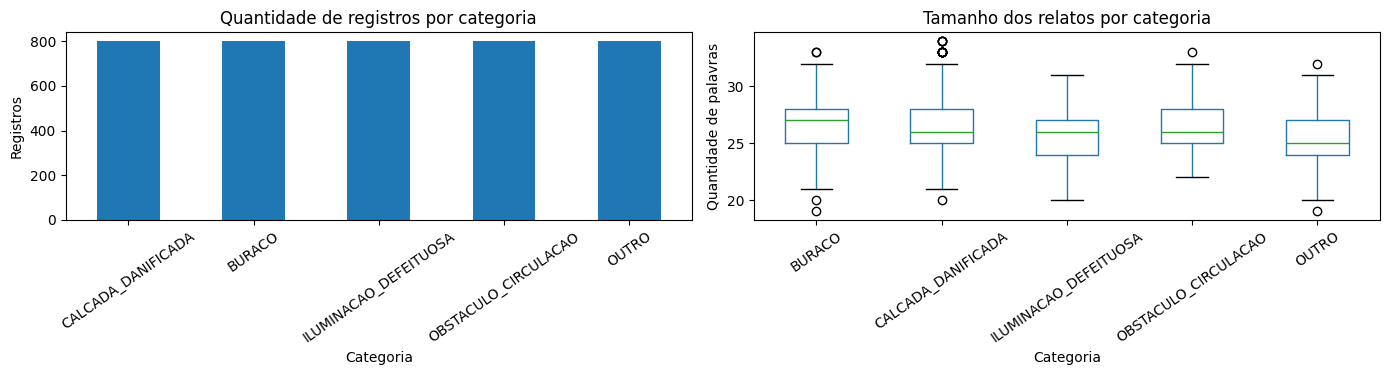

In [3]:
# 5. Análise exploratória
print("Dimensão da base:", df.shape)
print("\nValores ausentes:\n", df.isna().sum())
print("\nDuplicatas exatas:", int(df.duplicated().sum()))
print("\nDistribuição por categoria:\n", df["categoria"].value_counts().reindex(CATEGORIAS))

df["texto"] = (df["titulo"].fillna("").str.strip() + " " + df["descricao"].fillna("").str.strip()).str.strip()
df["tamanho_texto"] = df["texto"].str.split().str.len()
print("\nResumo do tamanho do texto:")
display(df["tamanho_texto"].describe().to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["categoria"].value_counts().reindex(CATEGORIAS).plot(kind="bar", ax=axes[0])
axes[0].set_title("Quantidade de registros por categoria")
axes[0].set_xlabel("Categoria")
axes[0].set_ylabel("Registros")
axes[0].tick_params(axis="x", rotation=35)
df.boxplot(column="tamanho_texto", by="categoria", ax=axes[1], grid=False, rot=35)
axes[1].set_title("Tamanho dos relatos por categoria")
axes[1].set_xlabel("Categoria")
axes[1].set_ylabel("Quantidade de palavras")
fig.suptitle("")
plt.tight_layout()
plt.show()

In [4]:
# 6. Verificações e preparação final
assert set(df["categoria"].unique()) == set(CATEGORIAS), "As classes não correspondem ao domínio do BRIDGE."
assert not df[["titulo", "descricao", "categoria"]].isna().any().any(), "Há valores ausentes."
assert (df["texto"].str.len() > 0).all(), "Há relatos vazios."

X = df["texto"]
y = df["categoria"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEMENTE, stratify=y
)
print(f"Treino: {len(X_treino)} | Teste: {len(X_teste)}")
print("Distribuição no teste:")
print(y_teste.value_counts(normalize=True).reindex(CATEGORIAS).round(3))

Treino: 3200 | Teste: 800
Distribuição no teste:
categoria
CALCADA_DANIFICADA       0.2
BURACO                   0.2
ILUMINACAO_DEFEITUOSA    0.2
OBSTACULO_CIRCULACAO     0.2
OUTRO                    0.2
Name: proportion, dtype: float64


## 5. Modelo, treinamento e seleção

O baseline `DummyClassifier` representa uma referência simples que sempre escolhe a classe mais frequente. O modelo proposto combina:

- **TF-IDF:** transforma palavras e sequências de até duas palavras em atributos numéricos, ponderando a frequência no documento e na base;
- **Regressão Logística:** classificador supervisionado multiclasse, adequado como linha de base interpretável para texto;
- **GridSearchCV:** compara configurações de `C` e faixa de n-gramas usando F1 macro com validação cruzada estratificada.

A base de teste fica separada durante o ajuste dos hiperparâmetros e é usada somente na avaliação final.

In [5]:
# 7. Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_treino), 1)), y_treino)
pred_baseline = baseline.predict(np.zeros((len(y_teste), 1)))
f1_baseline = f1_score(y_teste, pred_baseline, average="macro", zero_division=0)
print(f"F1-score macro do baseline: {f1_baseline:.4f}")

# 8. Pipeline e busca de hiperparâmetros
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, strip_accents="unicode", sublinear_tf=True, min_df=2)),
    ("logreg", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMENTE)),
])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
parametros = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "logreg__C": [0.5, 1.0, 2.0],
}

busca = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
busca.fit(X_treino, y_treino)
modelo = busca.best_estimator_
print("Melhores parâmetros:", busca.best_params_)
print(f"Melhor F1 macro médio na validação cruzada: {busca.best_score_:.4f}")

F1-score macro do baseline: 0.0667
Melhores parâmetros: {'logreg__C': 0.5, 'tfidf__ngram_range': (1, 1)}
Melhor F1 macro médio na validação cruzada: 1.0000


## 6. Avaliação do modelo

A avaliação apresenta acurácia, precisão macro, recall macro e F1 macro, além do relatório por categoria e matriz de confusão. O F1 macro é a métrica principal porque calcula o F1 de cada categoria e depois faz a média sem ponderar pelo tamanho da classe.

Métricas do conjunto de teste:
accuracy: 1.0000
precision_macro: 1.0000
recall_macro: 1.0000
f1_macro: 1.0000
f1_macro_baseline: 0.0667
f1_macro_cv_treino: 1.0000

Relatório por categoria:

                       precision    recall  f1-score   support

   CALCADA_DANIFICADA     1.0000    1.0000    1.0000       160
               BURACO     1.0000    1.0000    1.0000       160
ILUMINACAO_DEFEITUOSA     1.0000    1.0000    1.0000       160
 OBSTACULO_CIRCULACAO     1.0000    1.0000    1.0000       160
                OUTRO     1.0000    1.0000    1.0000       160

             accuracy                         1.0000       800
            macro avg     1.0000    1.0000    1.0000       800
         weighted avg     1.0000    1.0000    1.0000       800



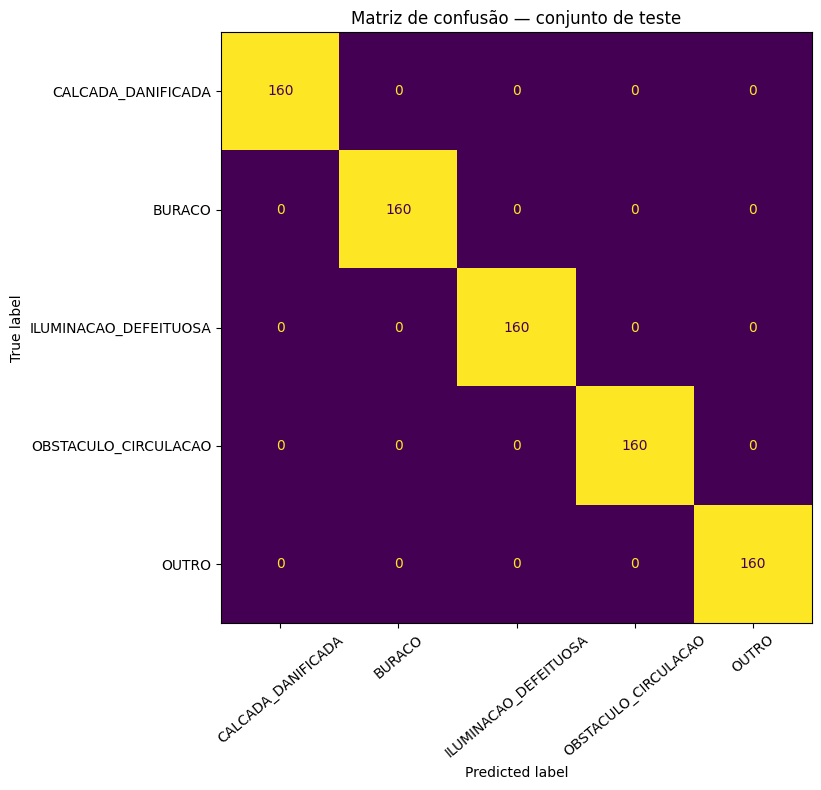

,Modelo,F1-score macro
0,DummyClassifier (baseline),0.066667
1,TF-IDF + Regressão Logística,1.000000


In [6]:
# 9. Avaliação final no conjunto de teste
pred_teste = modelo.predict(X_teste)
prob_teste = modelo.predict_proba(X_teste)

metricas = {
    "accuracy": float(accuracy_score(y_teste, pred_teste)),
    "precision_macro": float(precision_score(y_teste, pred_teste, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_teste, pred_teste, average="macro", zero_division=0)),
    "f1_macro": float(f1_score(y_teste, pred_teste, average="macro", zero_division=0)),
    "f1_macro_baseline": float(f1_baseline),
    "f1_macro_cv_treino": float(busca.best_score_),
}
print("Métricas do conjunto de teste:")
for nome, valor in metricas.items():
    print(f"{nome}: {valor:.4f}")

relatorio = classification_report(y_teste, pred_teste, labels=CATEGORIAS, zero_division=0, digits=4)
print("\nRelatório por categoria:\n")
print(relatorio)

matriz = confusion_matrix(y_teste, pred_teste, labels=CATEGORIAS)
display_matriz = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=CATEGORIAS)
fig, ax = plt.subplots(figsize=(10, 8))
display_matriz.plot(ax=ax, xticks_rotation=40, values_format="d", colorbar=False)
ax.set_title("Matriz de confusão — conjunto de teste")
plt.tight_layout()
plt.show()

comparacao = pd.DataFrame({
    "Modelo": ["DummyClassifier (baseline)", "TF-IDF + Regressão Logística"],
    "F1-score macro": [f1_baseline, metricas["f1_macro"]],
})
display(comparacao)

### Leitura crítica da métrica

Nesta execução sintética, o F1 macro e a acurácia podem chegar a 1,00 porque os textos foram gerados com vocabulário e templates específicos de cada classe, e combinações de padrões semelhantes podem aparecer nos dois subconjuntos. Isso demonstra que o pipeline aprendeu os padrões construídos pelo gerador; **não** prova que terá 100% de acerto em relatos reais ou em linguagem espontânea. A próxima validação necessária é com dados reais anonimizados e uma separação temporal ou por origem dos relatos.

## 7. Interpretação e análise de erros

Os coeficientes positivos mais altos de cada classe ajudam a identificar os termos que mais influenciam a decisão linear do modelo. Esta interpretação é indicativa: palavras isoladas não explicam todo o contexto do relato.

In [7]:
# 10. Termos mais associados a cada classe
vetorizador = modelo.named_steps["tfidf"]
classificador = modelo.named_steps["logreg"]
termos = np.array(vetorizador.get_feature_names_out())

for i, classe in enumerate(classificador.classes_):
    indices = np.argsort(classificador.coef_[i])[-12:][::-1]
    print(f"\n{classe}: {', '.join(termos[indices])}")

# 11. Análise de erros de classificação
erros = pd.DataFrame({
    "titulo": df.loc[X_teste.index, "titulo"].values,
    "descricao": df.loc[X_teste.index, "descricao"].values,
    "real": y_teste.values,
    "previsto": pred_teste,
})
erros = erros[erros["real"] != erros["previsto"]]
print(f"\nQuantidade de erros no teste: {len(erros)}")
if erros.empty:
    print("Nenhum erro foi observado neste conjunto sintético de teste.")
else:
    display(erros.head(12))


BURACO: buraco, asfalto, pavimento, veiculos, cratera, pista, pavimentacao, faixa, profundidade, cruzamento, ao, causar

CALCADA_DANIFICADA: piso, placas, revestimento, desnivel, calcada, deteriorado, passeio, rachaduras, concreto, fio, partes, permite

ILUMINACAO_DEFEITUOSA: iluminacao, luminaria, poste, luz, lampada, escuro, sem, noite, apagada, alguns, ficou, nao

OBSTACULO_CIRCULACAO: impede, bloqueia, rota, obra, caminho, deixados, passagem, bloqueiam, entulho, ocupa, obstaculo, caidos

OUTRO: sinalizacao, agua, vazamento, semaforo, boca, lobo, publica, lixeira, parada, precisa, residuos, lixo

Quantidade de erros no teste: 0
Nenhum erro foi observado neste conjunto sintético de teste.


## 8. Previsão de uma nova ocorrência

A previsão abaixo é uma demonstração. Em produção, o resultado deve ser tratado como **sugestão para triagem**, sujeito à revisão humana. A maior probabilidade retornada pelo modelo não é uma probabilidade calibrada nem garantia de acerto.

In [8]:
# 12. Exemplo de inferência com o mesmo formato de texto usado pelo backend
novo_titulo = "Luminária pública apagada na rua"
nova_descricao = "O poste não acende durante a noite e o trecho fica escuro para quem passa a pé."
texto_novo = (novo_titulo + " " + nova_descricao).strip()
classe_predita = modelo.predict([texto_novo])[0]
probabilidades = modelo.predict_proba([texto_novo])[0]
indice_top = int(np.argmax(probabilidades))
confianca_modelo = float(probabilidades[indice_top])

print("Título:", novo_titulo)
print("Descrição:", nova_descricao)
print("Categoria sugerida:", classe_predita)
print(f"Score/probabilidade máxima do modelo: {confianca_modelo:.4f}")
print("\nProbabilidades por categoria (não calibradas):")
for classe, prob in sorted(zip(modelo.classes_, probabilidades), key=lambda item: item[1], reverse=True):
    print(f"{classe}: {prob:.4f}")
assert classe_predita in CATEGORIAS

Título: Luminária pública apagada na rua
Descrição: O poste não acende durante a noite e o trecho fica escuro para quem passa a pé.
Categoria sugerida: ILUMINACAO_DEFEITUOSA
Score/probabilidade máxima do modelo: 0.9307

Probabilidades por categoria (não calibradas):
ILUMINACAO_DEFEITUOSA: 0.9307
OUTRO: 0.0258
BURACO: 0.0165
CALCADA_DANIFICADA: 0.0163
OBSTACULO_CIRCULACAO: 0.0108


## 9. Exportação dos artefatos

O pipeline exportado contém o TF-IDF e o classificador juntos, garantindo que a inferência use o mesmo pré-processamento do treinamento. O backend carrega esse artefato uma vez na inicialização. O notebook também exporta a base, as métricas, o relatório e metadados com origem e versão.

In [9]:
# 13. Exportação do modelo e evidências de avaliação
caminho_modelo = PASTA_ARTIFATOS / "bridge_text_classifier.joblib"
caminho_metricas = PASTA_ARTIFATOS / "metricas.json"
caminho_relatorio = PASTA_ARTIFATOS / "relatorio_classificacao.txt"
caminho_metadados = PASTA_ARTIFATOS / "metadados_modelo.json"

joblib.dump(modelo, caminho_modelo, compress=3)
with open(caminho_metricas, "w", encoding="utf-8") as arquivo:
    json.dump(metricas, arquivo, ensure_ascii=False, indent=2)
with open(caminho_relatorio, "w", encoding="utf-8") as arquivo:
    arquivo.write(relatorio)

metadados = {
    "nome": "BRIDGE Text Classifier",
    "versao": VERSAO_MODELO,
    "tarefa": "classificacao_multiclasse_de_texto",
    "entradas": ["titulo", "descricao"],
    "saida": "categoria_sugerida",
    "classes": CATEGORIAS,
    "algoritmo": "TfidfVectorizer + LogisticRegression",
    "semente": SEMENTE,
    "amostras_total": int(len(df)),
    "amostras_por_classe": int(AMOSTRAS_POR_CLASSE),
    "origem_dataset": "Sintético/simulado; gerado por templates e combinações aleatórias documentadas neste notebook; não são registros reais de cidadãos.",
    "divisao": {"treino": 0.8, "teste": 0.2, "estratificada": True},
    "validacao_cruzada": {"metodo": "StratifiedKFold", "n_splits": 3, "criterio": "f1_macro"},
    "melhores_parametros": {k: str(v) for k, v in busca.best_params_.items()},
    "metricas_teste": metricas,
    "versoes": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
    "observacao": "Resultados em dados sintéticos; não representam desempenho comprovado em dados reais. Probabilidades não calibradas.",
}
with open(caminho_metadados, "w", encoding="utf-8") as arquivo:
    json.dump(metadados, arquivo, ensure_ascii=False, indent=2)

print("Artefatos salvos:")
for caminho in [caminho_csv, caminho_modelo, caminho_metricas, caminho_relatorio, caminho_metadados]:
    print(f"- {caminho} ({caminho.stat().st_size:,} bytes)".replace(",", "."))

Artefatos salvos:
- C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml\dataset\bridge_ocorrencias_sinteticas.csv (746.136 bytes)
- C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml\artifacts\bridge_text_classifier.joblib (15.456 bytes)
- C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml\artifacts\metricas.json (169 bytes)
- C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml\artifacts\relatorio_classificacao.txt (580 bytes)
- C:\Users\Leo\Desktop\bridge\BRIDGE_CITIZENTECH\ia_ml\artifacts\metadados_modelo.json (1.446 bytes)


In [ ]:
# 14. Teste de carregamento do artefato exportado (smoke test)
modelo_recarregado = joblib.load(caminho_modelo)
pred_recarregada = modelo_recarregado.predict([texto_novo])[0]
assert pred_recarregada == classe_predita, "A previsão mudou após carregar o artefato."
assert set(modelo_recarregado.classes_) == set(CATEGORIAS), "As classes do artefato não correspondem ao BRIDGE."
print("OK: artefato recarregado e previsão reproduzida.")
print("Saída válida para a API:", {
    "categoria_sugerida": str(pred_recarregada),
    "confianca": round(confianca_modelo, 6),
    "versao_modelo": VERSAO_MODELO,
})

OK: artefato recarregado e previsão reproduzida.
Saída válida para a API: {'categoria_sugerida': 'ILUMINACAO_DEFEITUOSA', 'confianca': 0.930665, 'versao_modelo': 'bridge-text-classifier-1.0.0'}


: 

## 10. Integração com o BRIDGE e conclusão

O projeto contém um adaptador no backend que implementa o contrato `ClassificadorOcorrencia`. Quando `MODELO_IA_CAMINHO` aponta para o arquivo `.joblib`, a API carrega o pipeline na inicialização e usa `titulo` + `descricao` para produzir `categoria_sugerida` e `confianca`. `categoria_informada`, coordenadas, sinalizadores e imagem são ignorados pelo classificador textual.

A previsão é gravada nos campos de análise de IA já existentes (`ia_categoria_sugerida`, `ia_confianca`, `ia_versao_modelo`). O app já consome os campos de análise devolvidos pela API. O cadastro da ocorrência continua funcionando sem modelo configurado; em caso de falha de inferência, o backend marca a análise como `FALHOU` sem perder o relato.

### Limitações e próximos passos

1. Substituir/ complementar os exemplos sintéticos com ocorrências reais, anonimizadas e revisadas por especialistas.
2. Avaliar o modelo em dados reais coletados em período posterior ao treinamento, evitando que textos muito semelhantes apareçam no treino e teste.
3. Revisar confusões entre categorias e calibrar as probabilidades antes de exibir percentuais como confiança operacional.
4. Monitorar a qualidade e permitir correção humana da categoria sugerida.

### Conclusão

O experimento implementa um fluxo reproduzível de classificação textual alinhado aos campos e às classes do BRIDGE. O pipeline pode ser carregado pelo backend e sua saída aparece na resposta da ocorrência. Os resultados numéricos devem ser interpretados exclusivamente como evidência experimental em dados sintéticos, não como validação de desempenho em campo.